# SALA — Step 03: Anomaly Detector

**Goal:** Label each trading day as **normal (0)** or **abnormal (1)** using
a rolling Z-score on daily returns.

**Method:**
1. Daily return: $r_t = (P_t - P_{t-1}) / P_{t-1}$
2. Rolling mean and std over last $W$ days (default 20)
3. Z-score: $z_t = (r_t - \mu_W) / \sigma_W$
4. Label 1 if $|z_t| > \tau$ (default 2.5)

**Inputs:** `data/raw/{ticker}.csv`
**Outputs:** `data/processed/{ticker}.csv` (+ Return, Z_Score, Is_Anomaly)

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "src" / "config.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Could not find project root")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import matplotlib.pyplot as plt

from src.config import TICKERS, ANOMALY_WINDOW, ANOMALY_Z_THRESH, FIGURES_DIR
from src.models.anomaly import (
    process_all_assets,
    build_summary,
    save_summary,
    load_processed,
)

print(f"Project root: {PROJECT_ROOT}")
print(f"Tickers: {len(TICKERS)}")
print(f"Window: {ANOMALY_WINDOW}, Threshold: {ANOMALY_Z_THRESH}")

Project root: /Users/saleh/Documents/project/Sentiment-Aware Learning Automaton (SALA)
Tickers: 39
Window: 20, Threshold: 2.5


## 3. Run the detector on all assets

For each of the 39 assets, compute returns, Z-score, and the anomaly label,
then save the processed file to `data/processed/`.

In [2]:
results = process_all_assets()

Processing 39 assets (window=20, threshold=2.5)
-----------------------------------------------------------------
  [BTC-USD] 1460 rows, 36 anomalies -> BTC-USD.csv
  [ETH-USD] 1460 rows, 31 anomalies -> ETH-USD.csv
  [BNB-USD] 1460 rows, 30 anomalies -> BNB-USD.csv
  [SOL-USD] 1460 rows, 31 anomalies -> SOL-USD.csv
  [XRP-USD] 1460 rows, 42 anomalies -> XRP-USD.csv
  [ADA-USD] 1460 rows, 30 anomalies -> ADA-USD.csv
  [DOGE-USD] 1460 rows, 35 anomalies -> DOGE-USD.csv
  [TRX-USD] 1460 rows, 32 anomalies -> TRX-USD.csv
  [DOT-USD] 1460 rows, 30 anomalies -> DOT-USD.csv
  [POL28321-USD] 793 rows, 16 anomalies -> POL28321-USD.csv
  [AVAX-USD] 1460 rows, 26 anomalies -> AVAX-USD.csv
  [LINK-USD] 1460 rows, 27 anomalies -> LINK-USD.csv
  [USDT-USD] 1460 rows, 28 anomalies -> USDT-USD.csv
  [DX-Y.NYB] 1004 rows, 9 anomalies -> DX-Y_NYB.csv
  [EURUSD=X] 1038 rows, 14 anomalies -> EURUSD_X.csv
  [JPY=X] 1038 rows, 17 anomalies -> JPY_X.csv
  [GBPUSD=X] 1038 rows, 14 anomalies -> GBPUSD_X.csv
 

## 4. Inspect one asset (BTC-USD)

The first ~20 rows have `NaN` in `Z_Score` — this is the **warm-up period**
of the rolling window and is expected.

In [3]:
btc = results["BTC-USD"]
print(f"Shape: {btc.shape}")
print(f"Columns: {list(btc.columns)}")
print()
print(btc[["Close", "Return", "Rolling_Mean", "Rolling_Std", "Z_Score", "Is_Anomaly"]].head(10))
print()
print("Anomaly counts:")
print(btc["Is_Anomaly"].value_counts().rename({0: "Normal (0)", 1: "Abnormal (1)"}))

Shape: (1460, 10)
Columns: ['Close', 'High', 'Low', 'Open', 'Volume', 'Return', 'Rolling_Mean', 'Rolling_Std', 'Z_Score', 'Is_Anomaly']

                   Close    Return  Rolling_Mean  Rolling_Std  Z_Score  \
Date                                                                     
2022-01-01  47686.812500       NaN           NaN          NaN      NaN   
2022-01-02  47345.218750 -0.007163           NaN          NaN      NaN   
2022-01-03  46458.117188 -0.018737           NaN          NaN      NaN   
2022-01-04  45897.574219 -0.012066           NaN          NaN      NaN   
2022-01-05  43569.003906 -0.050734           NaN          NaN      NaN   
2022-01-06  43160.929688 -0.009366           NaN          NaN      NaN   
2022-01-07  41557.902344 -0.037141           NaN          NaN      NaN   
2022-01-08  41733.941406  0.004236           NaN          NaN      NaN   
2022-01-09  41911.601562  0.004257           NaN          NaN      NaN   
2022-01-10  41821.261719 -0.002155           NaN 

## 5. Visualize anomalies on BTC-USD

Red dots mark days flagged as abnormal.

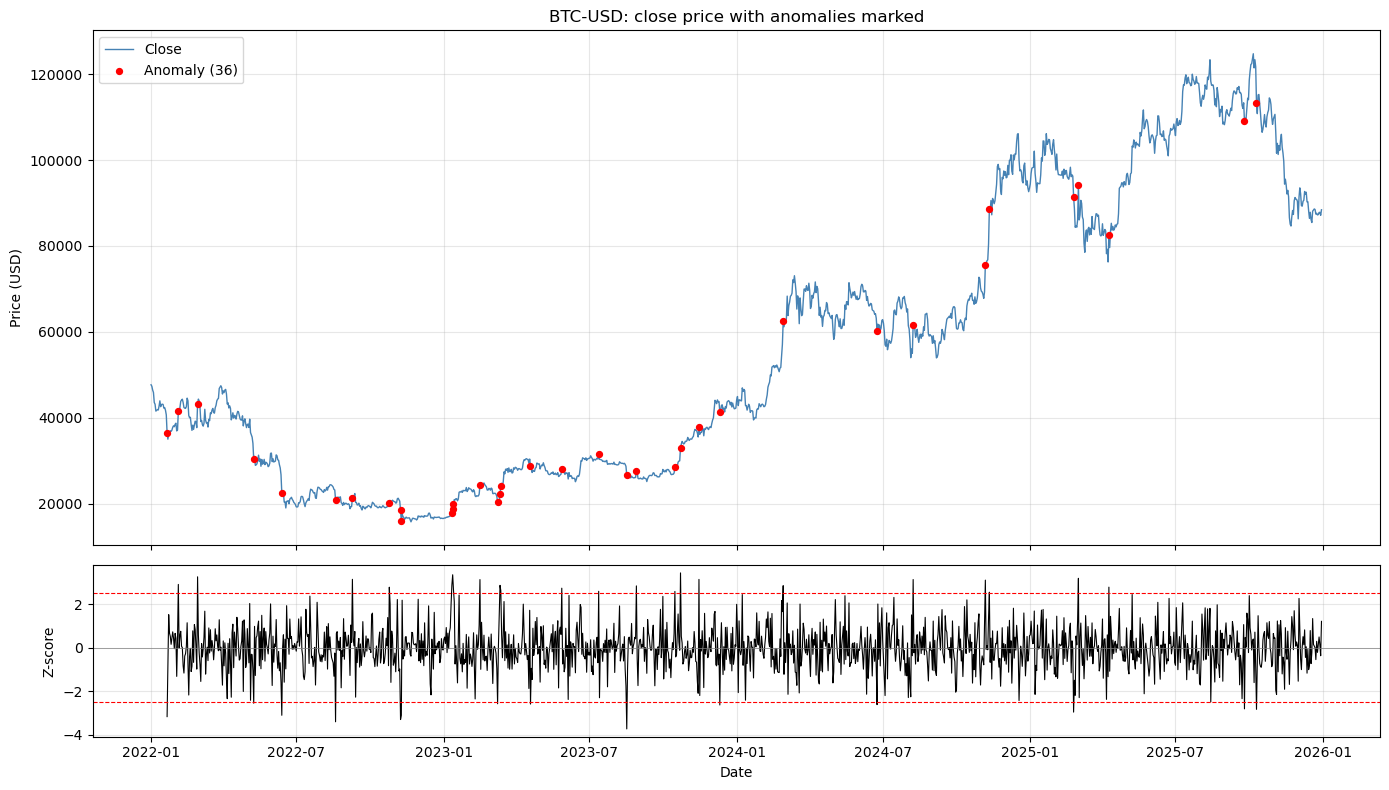

Figure saved: 03_anomaly_btc.png


In [4]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                                gridspec_kw={"height_ratios": [3, 1]})

# Price + anomalies
ax1.plot(btc.index, btc["Close"], color="steelblue", linewidth=1.0, label="Close")
anom = btc[btc["Is_Anomaly"] == 1]
ax1.scatter(anom.index, anom["Close"], color="red", s=18, zorder=3,
            label=f"Anomaly ({len(anom)})")
ax1.set_ylabel("Price (USD)")
ax1.set_title("BTC-USD: close price with anomalies marked")
ax1.grid(True, alpha=0.3)
ax1.legend(loc="upper left")

# Z-score
ax2.plot(btc.index, btc["Z_Score"], color="black", linewidth=0.8)
ax2.axhline( ANOMALY_Z_THRESH, color="red", linestyle="--", linewidth=0.8)
ax2.axhline(-ANOMALY_Z_THRESH, color="red", linestyle="--", linewidth=0.8)
ax2.axhline(0, color="gray", linewidth=0.5)
ax2.set_ylabel("Z-score")
ax2.set_xlabel("Date")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
fig_path = FIGURES_DIR / "03_anomaly_btc.png"
fig_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(fig_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"Figure saved: {fig_path.name}")

## 6. Summary across all assets

In [6]:
summary = build_summary(results)
save_summary(summary)
summary.head(15)

Saved: anomaly_summary.csv


,Ticker,Days,Anomalies,Anomaly_Rate_%,Max_|Z|
0,XRP-USD,1460,42,2.88,4.23
1,CNY=X,1038,28,2.70,3.84
2,BTC-USD,1460,36,2.47,3.72
3,DOGE-USD,1460,35,2.40,3.86
4,TRX-USD,1460,32,2.19,4.20
5,SOL-USD,1460,31,2.12,3.43
6,ETH-USD,1460,31,2.12,3.80
7,BNB-USD,1460,30,2.05,3.74
8,ADA-USD,1460,30,2.05,4.08
9,DOT-USD,1460,30,2.05,3.70


## 7. Anomaly rate per asset (bar chart)

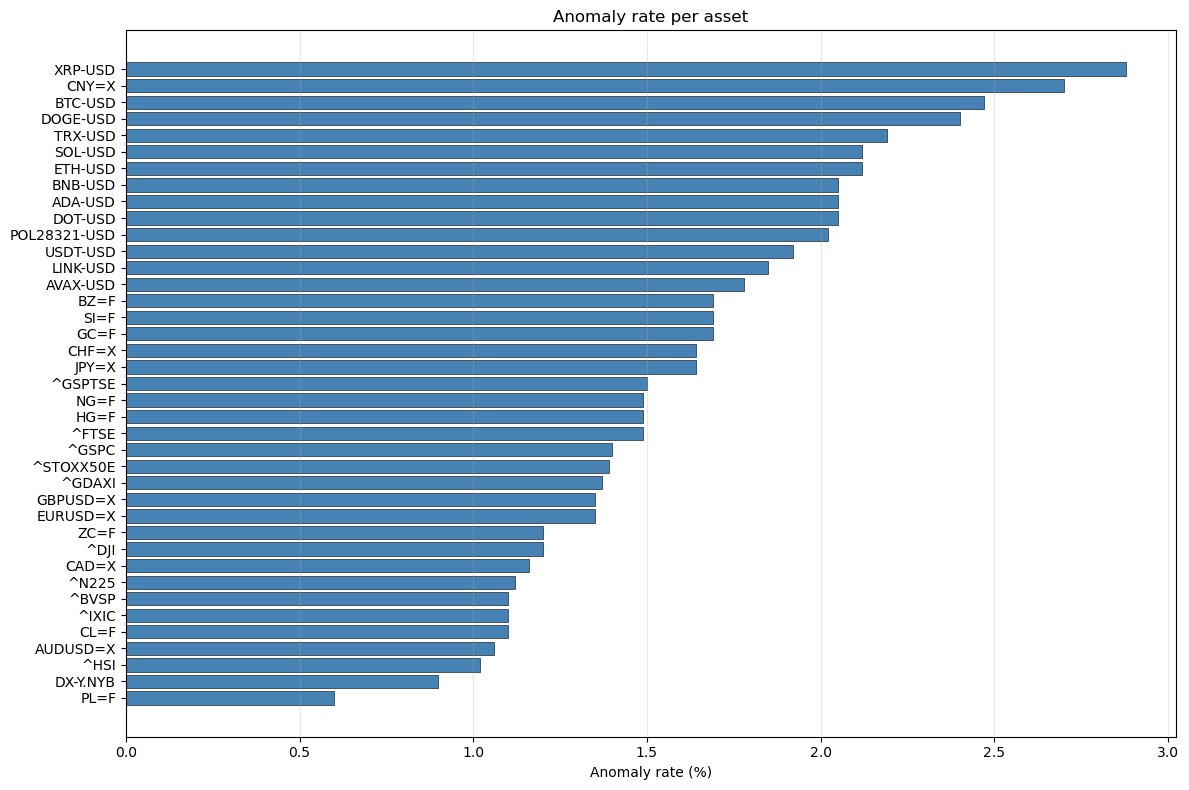

Figure saved: 03_anomaly_rates.png


In [7]:
fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(summary["Ticker"][::-1], summary["Anomaly_Rate_%"][::-1],
        color="steelblue", edgecolor="black", linewidth=0.4)
ax.set_xlabel("Anomaly rate (%)")
ax.set_title("Anomaly rate per asset")
ax.grid(True, axis="x", alpha=0.3)
plt.tight_layout()

fig_path = FIGURES_DIR / "03_anomaly_rates.png"
plt.savefig(fig_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"Figure saved: {fig_path.name}")